In [ ]:
import numpy as np
from scipy.special import jv, jn_zeros
from scipy.integrate import quad
from scipy.sparse.linalg import eigsh
from scipy.sparse import diags
from scipy.interpolate import UnivariateSpline
from joblib import Parallel, delayed
import matplotlib.pyplot as plt

In [ ]:
# =============================================
# Parámetros Físicos (Revisados)
# =============================================
D0 = 2e-9           # Coeficiente de difusión [m²/s]
R = 1e-6            # Radio del cilindro [m]
L = 100e-9          # Longitud axial [m]
z_c = 10e-9         # Altura crítica [m]
lambda_param = 0.2  # Parámetro de decaimiento [nm⁻¹]
kappa = 0.0         # Tasa de adsorción [s⁻¹]
rho0 = 0.75e-6      # Posición radial inicial [m] (alejada de R)
z0 = 15e-9          # Posición axial inicial [m] (lejos de z_c)
n_modes_radial = 16 # Modos radiales (reducido para prueba)
m_max = 15          # Modos axiales (reducido para prueba)
N_z = 1000          # Nodos en z
alpha_grid = 8.0     # Mayor densidad cerca de z_c
delta = 1.0e-9      # Transición más suave

In [ ]:
# =============================================
# 1. Malla Adaptativa Mejorada
# =============================================
j = np.arange(N_z)
z = z_c * (1 + np.sinh(alpha_grid * (j - N_z/2)/N_z) / np.sinh(alpha_grid/2))  # Simetría alrededor z_c

In [ ]:
# =============================================
# 2. Perfil de Difusión Suavizado
# =============================================
def diffusion_coefficient(z):
    S = 0.5 * (1 + np.tanh((z - z_c)/delta))
    return D0 * (np.exp(-lambda_param*z)*(1 - S) + 1.0*S)  # D0 continuo en z_c

D_values = diffusion_coefficient(z)

In [ ]:
# =============================================
# 3. Solución Radial (Verificación de Normalización)
# =============================================
alpha_zeros = jn_zeros(0, n_modes_radial)
alpha_n = alpha_zeros/R

# Cálculo preciso de normas
norm_J0_sq = np.zeros(n_modes_radial)
for n in range(n_modes_radial):
    integrand = lambda rho: rho * jv(0, alpha_n[n]*rho)**2
    norm_J0_sq[n] = quad(integrand, 0, R, epsrel=1e-6)[0]

In [ ]:
# =============================================
# 4. Solución Axial Estabilizada
# =============================================
eigenvalues_dict = {}
eigenvectors_dict = {}

for n in range(n_modes_radial):
    main_diag = np.zeros(N_z)
    upper_diag = np.zeros(N_z-1)
    lower_diag = np.zeros(N_z-1)
    
    # Discretización conservativa mejorada
    for j in range(1, N_z-1):
        h_prev = z[j] - z[j-1]
        h_next = z[j+1] - z[j]
        
        D_prev = 0.5*(D_values[j] + D_values[j-1])
        D_next = 0.5*(D_values[j] + D_values[j+1])
        
        main_diag[j] = (D_next/h_next + D_prev/h_prev)/(0.5*(h_prev + h_next)) + alpha_n[n]**2*D_values[j]
        upper_diag[j] = -D_next/(h_next * 0.5*(h_prev + h_next))
        lower_diag[j-1] = -D_prev/(h_prev * 0.5*(h_prev + h_next))

    # Condiciones de frontera
    main_diag[0] = D_values[0]/(z[1]-z[0]) + kappa*(z[1]-z[0])/2
    upper_diag[0] = -D_values[0]/(z[1]-z[0])
    
    main_diag[-1] = 1.0  # Dirichlet
    main_diag += 1e-8 * D0  # Estabilización
    
    A = diags([main_diag, upper_diag, lower_diag], [0, 1, -1], format='csr')
    
    # Cálculo de autovalores con precisión
    eigenvalues, eigenvectors = eigsh(A, k=m_max, which='SA', tol=1e-8, maxiter=100000, ncv=200)
    eigenvalues = np.clip(eigenvalues, 1e-16, None)  # Forzar positividad
    
    eigenvalues_dict[n] = eigenvalues
    eigenvectors_dict[n] = eigenvectors

In [ ]:
# =============================================
# 5. Coeficientes A_nm Corregidos
# =============================================
def compute_A_nm(n):
    A_nm = np.zeros(m_max)
    Z_norms = np.zeros(m_max)
    
    # Cálculo preciso de normas axiales
    for m in range(m_max):
        integrand = lambda z_val: UnivariateSpline(z, eigenvectors_dict[n][:, m], s=0)(z_val)**2 / diffusion_coefficient(z_val)
        Z_norms[m], _ = quad(integrand, z[0], z[-1], epsrel=1e-6, limit=500)
    
    # Evaluación segura en z0
    Z_m_z0 = np.array([UnivariateSpline(z, eigenvectors_dict[n][:, m], s=0)(z0) for m in range(m_max)])
    J0_rho0 = jv(0, alpha_n[n]*rho0)
    
    for m in range(m_max):
        if Z_norms[m] < 1e-20:  # Descarta modos no normalizados
            A_nm[m] = 0.0
        else:
            A_nm[m] = (J0_rho0 * Z_m_z0[m]) / (2*np.pi * rho0 * norm_J0_sq[n] * Z_norms[m])
    
    return A_nm

A_nm = Parallel(n_jobs=-1)(delayed(compute_A_nm)(n) for n in range(n_modes_radial))

In [ ]:
# =============================================
# 6. Cálculo de G(t) Mejorado
# =============================================
def compute_G(t, N_quad=16):
    # Cuadratura adaptativa en coordenadas cilíndricas
    rho_nodes, rho_weights = np.polynomial.legendre.leggauss(N_quad)
    rho_nodes = 0.5*R*(rho_nodes + 1)
    rho_weights *= 0.5*R
    
    z_nodes, z_weights = np.polynomial.legendre.leggauss(N_quad)
    z_nodes = z[0] + (z[-1]-z[0])*(z_nodes + 1)/2
    z_weights *= 0.5*(z[-1]-z[0])
    
    # Precalcular todas las evaluaciones necesarias
    Z_interps = [[UnivariateSpline(z, eigenvectors_dict[n][:, m], s=0) for m in range(m_max)] for n in range(n_modes_radial)]
    
    total = 0.0
    for i in range(N_quad):
        rho_i = rho_nodes[i]
        for j in range(N_quad):
            z_i = z_nodes[j]
            f_ij = (3*z_i**2 - rho_i**2)/(rho_i**2 + z_i**2 + 1e-30)**2.5  # Evita división por cero
            
            sum_term = 0.0
            for n in range(n_modes_radial):
                J0 = jv(0, alpha_n[n]*rho_i)
                decay = np.exp(-(alpha_n[n]**2*D0 + eigenvalues_dict[n])*t)
                Z_m = np.array([Z_interps[n][m](z_i) for m in range(m_max)])
                
                sum_term += np.dot(A_nm[n] * J0 * Z_m, decay)
            
            total += rho_weights[i] * z_weights[j] * f_ij * sum_term
    
    return (5/(16*np.pi)) * max(total, 1e-40)

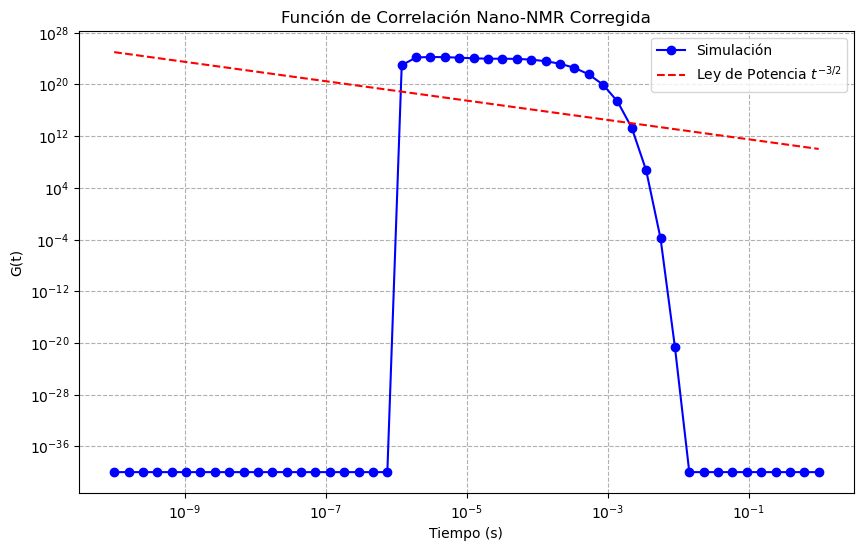

In [1]:
# =============================================
# 7. Simulación y Visualización
# =============================================
if __name__ == "__main__":
    plt.figure(figsize=(8,5))
    plt.plot(z*1e9, D_values/D0, 'b-', lw=1.5)
    plt.xlabel('z (nm)')
    plt.ylabel('D(z)/D₀')
    plt.title('Perfil de Difusión')
    plt.grid(ls='--', alpha=0.7)
    plt.savefig('Dz_profile_v3.pdf', bbox_inches='tight')
    plt.close()
    
    plt.figure(figsize=(8,5))
    for n in range(3):
        evals = eigenvalues_dict[n][:20]
        plt.semilogy(evals, 'o-', label=f'n={n}')
    plt.xlabel('Modo Axial')
    plt.ylabel('Autovalor (s⁻¹)')
    plt.title('Espectro de Autovalores')
    plt.legend()
    plt.grid(ls='--', alpha=0.7)
    plt.savefig('eigenvalues_v3.pdf', bbox_inches='tight')
    plt.close()
    
    
    # Generar datos
    t_values = np.logspace(-10, -0.01, 50)
    G_values = Parallel(n_jobs=-1)(delayed(compute_G)(t) for t in t_values)
    
    # Filtrar valores no físicos
    G_values = np.nan_to_num(G_values, posinf=0, neginf=0)
    G_values = np.clip(G_values, 1e-40, None)

    np.savetxt('G_vs_t_v3.dat', np.c_[t_values, G_values], 
               header='Tiempo(s) G(t)', fmt='%.3e')
    
    # Gráfica resultante
    plt.figure(figsize=(10, 6))
    plt.loglog(t_values, G_values, 'bo-', label='Simulación')
    plt.plot(t_values, 1e10*t_values**-1.5, 'r--', label='Ley de Potencia $t^{-3/2}$')
    plt.xlabel('Tiempo (s)')
    plt.ylabel('G(t)')
    plt.title('Función de Correlación Nano-NMR Corregida')
    plt.legend()
    plt.grid(True, which='both', ls='--')
    plt.savefig('Gt_result_v3.pdf', bbox_inches='tight')
    plt.show()